In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os, pickle
d = "/content/drive/MyDrive/radar-trafico/data/raw/session2_center"

# 1. ¿El vídeo está completo?
print(os.path.getsize(f"{d}/video.avi") == 9508744968)

# 2. ¿El pkl se abre?
with open(f"{d}/gt_data.pkl", "rb") as f:
    gt = pickle.load(f, encoding="latin1")
print(type(gt), gt.keys() if isinstance(gt, dict) else len(gt))

True
<class 'dict'> dict_keys(['distanceMeasurement', 'measurementLines', 'cars', 'fps', 'invalidLanes', 'laneDivLines'])


In [7]:
!mkdir -p /content/drive/MyDrive/radar-trafico/data/raw
!cp -r /content/brno/2016-ITS-BrnoCompSpeed/dataset/session2_center /content/drive/MyDrive/radar-trafico/data/raw/

cp: cannot stat '/content/brno/2016-ITS-BrnoCompSpeed/dataset/session2_center': No such file or directory


In [8]:
print(gt["fps"])
car = gt["cars"][39]
print(car.keys())
print(car)

50.0
dict_keys(['acceleration', 'intersections', 'carId', 'timeIntersectionLastShifted', 'valid', 'laneIndex', 'speed'])
{'acceleration': -0.523, 'intersections': [{'measurementLineId': 4, 'videoTime': 466.216972}, {'measurementLineId': 0, 'videoTime': 467.410116}], 'carId': 40, 'timeIntersectionLastShifted': 467.410116, 'valid': True, 'laneIndex': {1}, 'speed': 84.4812}


(1080, 1920, 3) (1080, 1920) [  0 255]


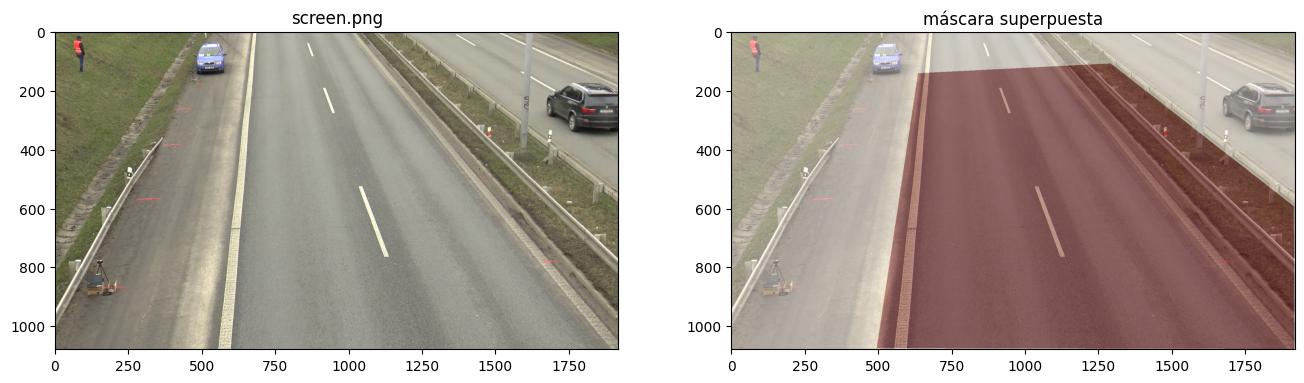

In [9]:
import numpy as np
import cv2, matplotlib.pyplot as plt

screen = cv2.cvtColor(cv2.imread(f"{d}/screen.png"), cv2.COLOR_BGR2RGB)
mask = cv2.imread(f"{d}/video_mask.png", cv2.IMREAD_GRAYSCALE)
print(screen.shape, mask.shape, np.unique(mask))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].imshow(screen); ax[0].set_title("screen.png")
ax[1].imshow(screen); ax[1].imshow(mask, alpha=0.4, cmap="Reds"); ax[1].set_title("máscara superpuesta")
plt.show()

In [10]:
car = gt["cars"][600]
print(car.keys())
print(car["acceleration"])
print(car["intersections"])
print(car["carId"])
print(car["timeIntersectionLastShifted"])
print(car["valid"])
print(car["laneIndex"])
print(car["speed"])

dict_keys(['acceleration', 'intersections', 'carId', 'timeIntersectionLastShifted', 'valid', 'laneIndex', 'speed'])
-0.243
[{'measurementLineId': 4, 'videoTime': 1681.359062}, {'measurementLineId': 0, 'videoTime': 1682.705316}]
601
1682.705316
True
{0}
74.8728


In [23]:
intersections = car["intersections"]
print(intersections)

def tiempoCoche(intersections):         # tiempo que tarda en cruzar las lineas 0 y 4 del dataset

    tiempos = []
    for intersection in intersections:
        tiempos.append(intersection["videoTime"])

    linea0 = tiempos[1]
    linea4 = tiempos[0]

    return linea4, linea0

print(tiempoCoche(intersections))

[{'measurementLineId': 4, 'videoTime': 1681.359062}, {'measurementLineId': 0, 'videoTime': 1682.705316}]
(1681.359062, 1682.705316)


In [56]:
from posix import write
FRAMES_POR_SEGUNDO = 100

def leer_frames(rutaVideo, tInicio, tFinal):
    cap = cv2.VideoCapture(rutaVideo)

    frameInicio = round(tInicio * FRAMES_POR_SEGUNDO)
    frameFinal = round(tFinal * FRAMES_POR_SEGUNDO)

    cap.set(cv2.CAP_PROP_POS_FRAMES, frameInicio)

    for i in range(frameInicio, frameFinal):
        ok, frame = cap.read()

        if not ok:
          break

        yield i, i / FRAMES_POR_SEGUNDO, frame

    cap.release()

def mostrar_clip(rutaVideo, tInicio, tFinal, modelo, salida="clip.mp4"):
  writer = None

  for i, t, frame in leer_frames(rutaVideo, tInicio, tFinal):

    resultado = modelo(frame, classes=[2, 3, 5, 7], verbose=False)[0]  # importante, filtro para vehiculos
    frame = resultado.plot()

    if writer is None:
      h, w = frame.shape[:2]
      writer = cv2.VideoWriter(salida, cv2.VideoWriter_fourcc(*"mp4v"), 100, (w, h))
    writer.write(frame)
  writer.release()

car = gt["cars"][600]
intersections = car["intersections"]
tInicio, tFinal = tiempoCoche(intersections)

In [58]:
from IPython.display import Video
!rm -f clip.mp4 clip_h264.mp4

modelo = YOLO("yolo11n.pt")

mostrar_clip("/content/drive/MyDrive/radar-trafico/data/raw/session2_center/video.avi", tInicio, tFinal, modelo)

!ffprobe -v error -count_frames -select_streams v:0 -show_entries stream=nb_read_frames -of csv=p=0 clip.mp4
!ffmpeg -y -loglevel error -i clip.mp4 -c:v libx264 clip_h264.mp4
Video("clip_h264.mp4", embed=True)

135
